In [ ]:
import pandas as pd, torch, torchvision, matplotlib.pyplot as plt

In [ ]:
from torchvision.datasets import OxfordIIITPet

dataset = OxfordIIITPet(root="data/", split="trainval", download=True)


100%|██████████| 792M/792M [00:20<00:00, 37.8MB/s]
100%|██████████| 19.2M/19.2M [00:00<00:00, 19.3MB/s]


In [ ]:
image, label = dataset[0]


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
import torchvision.transforms.v2 as T

resize = T.Compose([
    T.Resize((64, 64)), T.ToImage(),
    T.ToDtype(torch.float32, scale=True)])
transformed_data = OxfordIIITPet(root="data/", split="trainval", transform=resize)
train_loader = DataLoader(
    Subset(transformed_data, range(400)), batch_size=16, shuffle=True)

In [ ]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=37): # we have 37 different breeds in the dataset
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.network = nn.Linear(32 * 16 * 16, num_classes)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))   # 64 → 32
        x = self.pool(torch.relu(self.conv2(x)))   # 32 → 16
        return self.network(x.flatten(1))

model = SimpleCNN()
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
losses = []
for epoch in range(3):
    for images, labels in train_loader:
        optimizer.zero_grad()
        preds = model(images)
        loss = loss_fn(preds, labels)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
print(losses)

[3.5736732482910156, 3.738301992416382, 7.489406585693359, 2.5089080333709717, 2.5989906787872314, 2.264988422393799, 2.4461750984191895, 2.125054121017456, 2.2887282371520996, 2.506946325302124, 2.182710886001587, 2.0460522174835205, 2.2225570678710938, 2.2025086879730225, 2.2546732425689697, 2.390202045440674, 2.1366822719573975, 2.399571418762207, 2.1728851795196533, 2.246931552886963, 2.2393243312835693, 2.044796943664551, 2.158233880996704, 2.256239414215088, 2.2799129486083984, 2.1174745559692383, 1.9333678483963013, 2.200242757797241, 2.0968704223632812, 1.9639495611190796, 1.926295280456543, 2.5793228149414062, 1.9149049520492554, 1.8309577703475952, 1.93058443069458, 1.898444414138794, 2.1249771118164062, 1.999327540397644, 2.2064249515533447, 2.163559913635254, 1.7415281534194946, 1.8232996463775635, 2.0264222621917725, 2.138028860092163, 2.0510072708129883, 2.158734083175659, 1.768985629081726, 1.643692970275879, 1.9934101104736328, 2.082348108291626, 1.795740008354187, 1.90

In [ ]:

augment = T.Compose([
    T.RandomHorizontalFlip(p=0.5),
    T.RandomResizedCrop(224, scale=(0.8, 1.0)),
    T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
    T.RandomErasing(p=0.2),
])


(np.float64(-0.5), np.float64(905.5), np.float64(453.5), np.float64(-0.5))

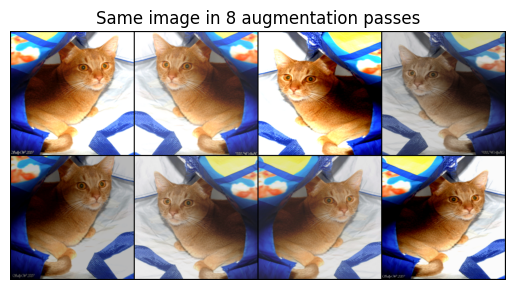

In [ ]:
from torchvision.utils import make_grid
import torchvision.transforms.functional as F

samples = [F.to_tensor(augment(image)) for _ in range(8)]
grid = make_grid(tensor=samples, nrow=4)
plt.imshow(grid.permute(1, 2, 0))
plt.title("Same image in 8 augmentation passes")
plt.axis('off')